In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

In [3]:
import pandas as pd

df = pd.read_excel("/content/Online Retail.xlsx")

print(df.head())
print("Dataset Shape:", df.shape)
print(df.columns)

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
Dataset Shape: (541909, 8)
Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')


In [4]:
# Remove rows with missing customer IDs
df = df.dropna(subset=['CustomerID']).copy()

# Remove cancelled invoices
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')].copy()

# Remove invalid quantities and prices
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)].copy()

# Convert invoice date into datetime
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Calculate total transaction value
df['TotalAmount'] = df['Quantity'] * df['UnitPrice']

print(df.head())
print("Cleaned dataset shape:", df.shape)

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  TotalAmount  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom        15.30  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom        20.34  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom        22.00  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom        20.34  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom        20.34  
Cleaned dataset shape: (397884, 9)


In [5]:
# Set reference date as one day after the last transaction
reference_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm = df.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda x: (reference_date - x.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('TotalAmount', 'sum')
).reset_index()

print(rfm.head())
print("Total customers:", len(rfm))

   CustomerID  Recency  Frequency  Monetary
0     12346.0      326          1  77183.60
1     12347.0        2          7   4310.00
2     12348.0       75          4   1797.24
3     12349.0       19          1   1757.55
4     12350.0      310          1    334.40
Total customers: 4338


In [6]:
# Keep only customers with valid positive RFM values
rfm = rfm[
    (rfm['Recency'] >= 0) &
    (rfm['Frequency'] > 0) &
    (rfm['Monetary'] > 0)
].copy()

rfm_features = rfm[['Recency', 'Frequency', 'Monetary']].copy()

# Reduce skewness
rfm_log = np.log1p(rfm_features)

# Scale the features
scaler = RobustScaler()
X_scaled = scaler.fit_transform(rfm_log)

print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (4338, 3)


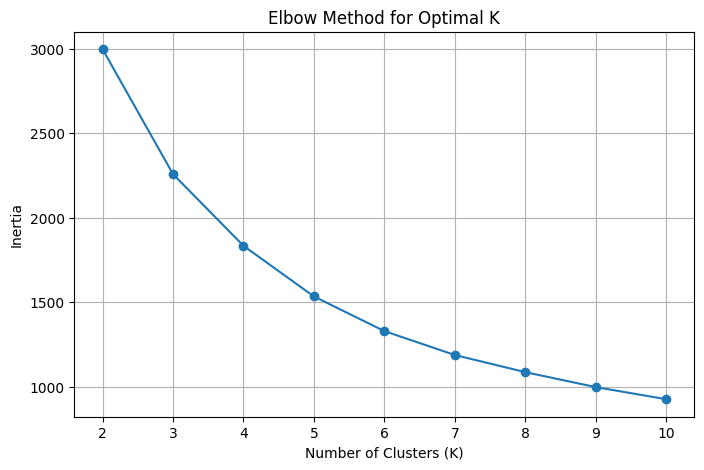

In [7]:
inertia = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), inertia, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal K')
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

In [8]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)

print(rfm.head())
print(rfm['KMeans_Cluster'].value_counts().sort_index())

   CustomerID  Recency  Frequency  Monetary  KMeans_Cluster
0     12346.0      326          1  77183.60               3
1     12347.0        2          7   4310.00               0
2     12348.0       75          4   1797.24               3
3     12349.0       19          1   1757.55               2
4     12350.0      310          1    334.40               1
KMeans_Cluster
0     732
1    1558
2     843
3    1205
Name: count, dtype: int64


In [9]:
kmeans_summary = rfm.groupby('KMeans_Cluster').agg(
    Customer_Count=('CustomerID', 'count'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary=('Monetary', 'mean')
).round(2)

print(kmeans_summary)

                Customer_Count  Avg_Recency  Avg_Frequency  Avg_Monetary
KMeans_Cluster                                                          
0                          732        12.75          13.54       8015.66
1                         1558       182.06           1.30        308.87
2                          843        17.72           2.26        576.03
3                         1205        77.60           3.89       1723.76


In [10]:
dbscan = DBSCAN(
    eps=0.5,
    min_samples=10
)

rfm['DBSCAN_Cluster'] = dbscan.fit_predict(X_scaled)

print(rfm['DBSCAN_Cluster'].value_counts().sort_index())

DBSCAN_Cluster
-1      35
 0    4303
Name: count, dtype: int64


In [11]:
dbscan_summary = rfm.groupby('DBSCAN_Cluster').agg(
    Customer_Count=('CustomerID', 'count'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary=('Monetary', 'mean')
).round(2)

print(dbscan_summary)

                Customer_Count  Avg_Recency  Avg_Frequency  Avg_Monetary
DBSCAN_Cluster                                                          
-1                          35        53.94          48.49      64751.32
 0                        4303        92.85           3.91       1544.30


In [12]:
print("K-Means Cluster Distribution:")
print(rfm['KMeans_Cluster'].value_counts().sort_index())

print("\nDBSCAN Cluster Distribution:")
print(rfm['DBSCAN_Cluster'].value_counts().sort_index())

K-Means Cluster Distribution:
KMeans_Cluster
0     732
1    1558
2     843
3    1205
Name: count, dtype: int64

DBSCAN Cluster Distribution:
DBSCAN_Cluster
-1      35
 0    4303
Name: count, dtype: int64


In [13]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Explained variance ratio:", pca.explained_variance_ratio_)

print(
    "Total variance explained:",
    pca.explained_variance_ratio_.sum()
)

Explained variance ratio: [0.75324728 0.18765544]
Total variance explained: 0.9409027182891794


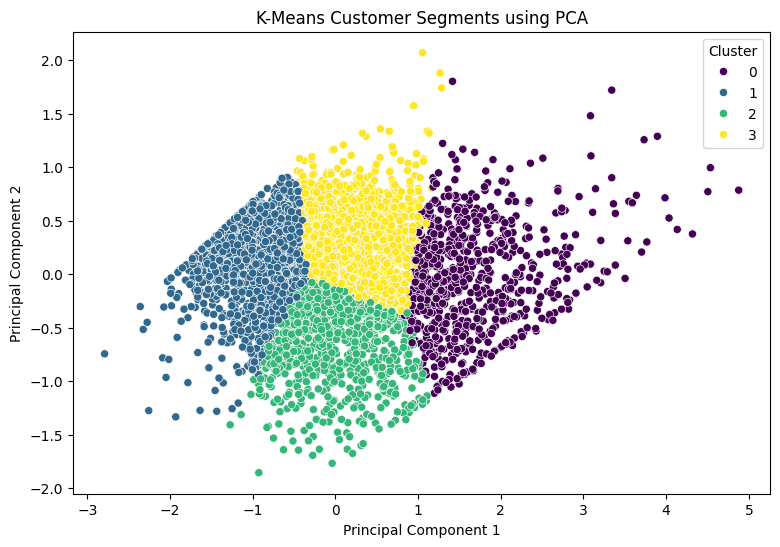

In [14]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=rfm['KMeans_Cluster'],
    palette='viridis',
    s=35
)

plt.title('K-Means Customer Segments using PCA')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')
plt.show()

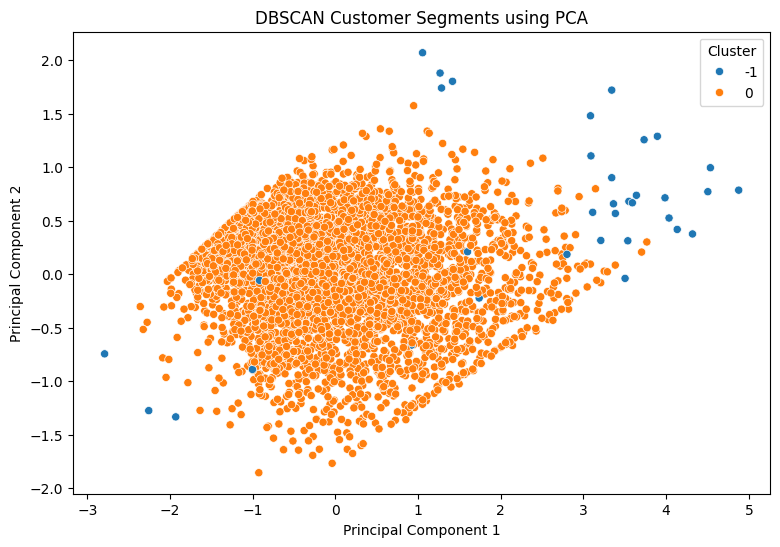

In [15]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=rfm['DBSCAN_Cluster'],
    palette='tab10',
    s=35
)

plt.title('DBSCAN Customer Segments using PCA')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')
plt.show()

In [16]:
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate='auto',
    init='pca',
    random_state=42
)

X_tsne = tsne.fit_transform(X_scaled)

print("t-SNE output shape:", X_tsne.shape)

t-SNE output shape: (4338, 2)


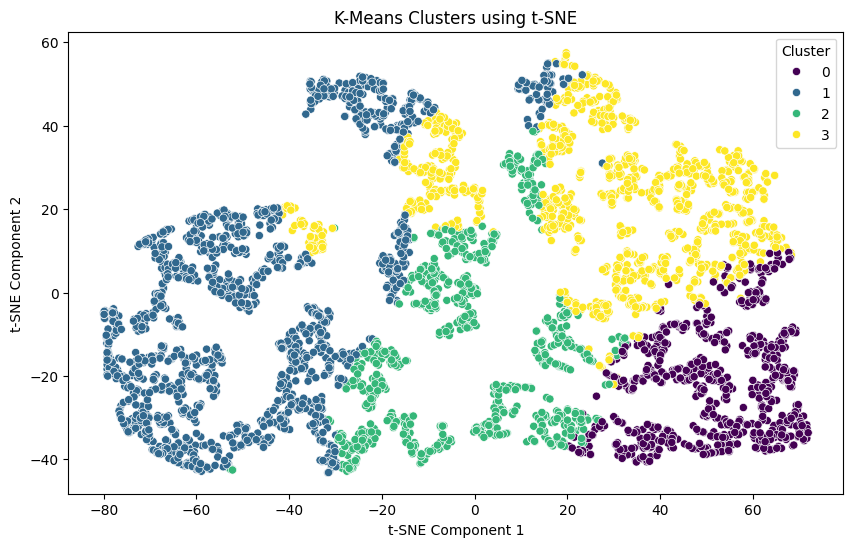

In [17]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=X_tsne[:, 0],
    y=X_tsne[:, 1],
    hue=rfm['KMeans_Cluster'],
    palette='viridis',
    s=35
)

plt.title('K-Means Clusters using t-SNE')
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.legend(title='Cluster')
plt.show()

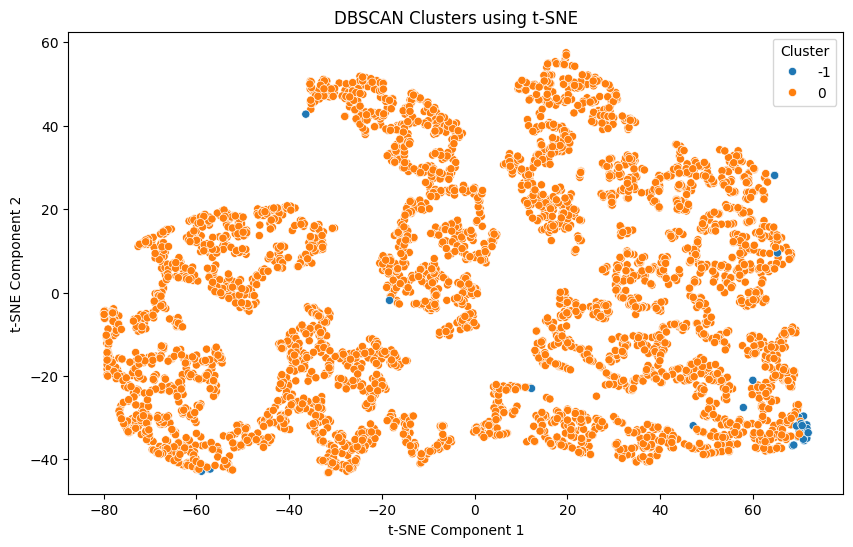

In [18]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=X_tsne[:, 0],
    y=X_tsne[:, 1],
    hue=rfm['DBSCAN_Cluster'],
    palette='tab10',
    s=35
)

plt.title('DBSCAN Clusters using t-SNE')
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.legend(title='Cluster')
plt.show()

In [19]:
# Evaluate K-Means
kmeans_labels = rfm['KMeans_Cluster'].to_numpy()

kmeans_score = silhouette_score(
    X_scaled,
    kmeans_labels
)

print("K-Means Silhouette Score:", round(kmeans_score, 4))

K-Means Silhouette Score: 0.3336


In [20]:
dbscan_labels = rfm['DBSCAN_Cluster'].to_numpy()

# Exclude noise points
mask = dbscan_labels != -1

valid_labels = dbscan_labels[mask]
valid_data = X_scaled[mask]

if len(valid_labels) > 1 and len(np.unique(valid_labels)) > 1:
    dbscan_score = silhouette_score(
        valid_data,
        valid_labels
    )

    print("DBSCAN Silhouette Score:", round(dbscan_score, 4))
else:
    print("DBSCAN Silhouette Score cannot be calculated meaningfully.")

DBSCAN Silhouette Score cannot be calculated meaningfully.


In [21]:
persona_summary = rfm.groupby('KMeans_Cluster').agg(
    Customer_Count=('CustomerID', 'count'),
    Recency=('Recency', 'mean'),
    Frequency=('Frequency', 'mean'),
    Monetary=('Monetary', 'mean')
).round(2)

# Use overall customer averages as simple reference points
avg_recency = rfm['Recency'].median()
avg_frequency = rfm['Frequency'].median()
avg_monetary = rfm['Monetary'].median()


def assign_persona(row):
    if (
        row['Monetary'] >= avg_monetary
        and row['Frequency'] >= avg_frequency
        and row['Recency'] <= avg_recency
    ):
        return "Champions"

    elif (
        row['Monetary'] >= avg_monetary
        and row['Frequency'] < avg_frequency
    ):
        return "Big Spenders / Potential Loyalists"

    elif (
        row['Frequency'] >= avg_frequency
        and row['Recency'] <= avg_recency
    ):
        return "Loyal Active Customers"

    elif row['Recency'] > avg_recency:
        return "At-Risk / Inactive Customers"

    else:
        return "Regular / Developing Customers"


persona_summary['Marketing_Persona'] = persona_summary.apply(
    assign_persona,
    axis=1
)

print(persona_summary)

                Customer_Count  Recency  Frequency  Monetary  \
KMeans_Cluster                                                 
0                          732    12.75      13.54   8015.66   
1                         1558   182.06       1.30    308.87   
2                          843    17.72       2.26    576.03   
3                         1205    77.60       3.89   1723.76   

                           Marketing_Persona  
KMeans_Cluster                                
0                                  Champions  
1               At-Risk / Inactive Customers  
2                     Loyal Active Customers  
3               At-Risk / Inactive Customers  


In [22]:
# Combine PCA and t-SNE coordinates with customer data
rfm['PCA_1'] = X_pca[:, 0]
rfm['PCA_2'] = X_pca[:, 1]

rfm['TSNE_1'] = X_tsne[:, 0]
rfm['TSNE_2'] = X_tsne[:, 1]

# Add marketing persona to each customer
persona_mapping = persona_summary['Marketing_Persona'].to_dict()

rfm['Marketing_Persona'] = rfm['KMeans_Cluster'].map(
    persona_mapping
)

# Save results
rfm.to_csv('customer_segmentation_results.csv', index=False)

print("Customer segmentation results saved successfully!")
print(rfm.head())

Customer segmentation results saved successfully!
   CustomerID  Recency  Frequency  Monetary  KMeans_Cluster  DBSCAN_Cluster  \
0     12346.0      326          1  77183.60               3              -1   
1     12347.0        2          7   4310.00               0               0   
2     12348.0       75          4   1797.24               3               0   
3     12349.0       19          1   1757.55               2               0   
4     12350.0      310          1    334.40               1               0   

      PCA_1     PCA_2     TSNE_1     TSNE_2             Marketing_Persona  
0  1.054541  2.068997  64.689018  28.125507  At-Risk / Inactive Customers  
1  1.739617 -0.542549  39.550858 -37.545906                     Champions  
2  0.372866  0.511399  46.737099  24.440481  At-Risk / Inactive Customers  
3  0.220042 -0.203986 -30.228676  15.461193        Loyal Active Customers  
4 -1.102225  0.490058 -66.848396  10.320123  At-Risk / Inactive Customers  
